In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# Colab 会自动选 /content；本地运行可自行修改 DATA_DIR。
DATA_DIR = Path('/content') if Path('/content').exists() else Path('/Users/liuxintong/Downloads')
OUT_DIR = Path('/content/step3_outputs') if Path('/content').exists() else Path.cwd() / 'outputs'
OUT_DIR.mkdir(parents=True, exist_ok=True)

B = 3000                  # 每个格子抽样次数；不是新增浮标数
SEED = 20261105           # 固定随机种子，保证可重复
MIN_N_PLOT = 10           # 仅为少样本展示提示，不是 Step 4 推导的达标门槛
TARGET_CMPS = 5.0
LON0, LAT0 = 115.0, 15.0  # 已通过原始数据核对网格原点
NX, NY = 30, 25           # 115–145°E，15–40°N，最后一格包含上边界

agg_vel = pd.read_parquet(DATA_DIR / 'agg_vel_1deg.parquet')
print(f'速度聚合表：{len(agg_vel):,} 行')
print(agg_vel.head().to_string(index=False))

速度聚合表：23,886 行
 iy  ix              id    enso   n    sum_ve    sum_vn
  0   0           49632 Neutral  70 -1.539700  1.969500
  0   0          139801 El Niño 119 29.830900 -6.839100
  0   0          139804 El Niño 147 29.963699 12.354700
  0   0 300234060291780 Neutral  74 14.902200 30.791599
  0   0 300234060999470 Neutral  76 -6.300600 32.247200


In [ ]:
keys = ['iy', 'ix', 'id']
required = keys + ['n', 'sum_ve', 'sum_vn']
assert set(required).issubset(agg_vel.columns), '列名不对，请确认读取的是速度文件。'
assert agg_vel[required].notna().all().all(), '聚合表有缺失值，先检查。'
assert np.isfinite(agg_vel[['n', 'sum_ve', 'sum_vn']].to_numpy()).all()
assert (agg_vel['n'] > 0).all()
assert (agg_vel['n'] % 1 == 0).all()
assert agg_vel['iy'].between(0, NY - 1).all() and agg_vel['ix'].between(0, NX - 1).all()

vel = (agg_vel.astype({'sum_ve': 'float64', 'sum_vn': 'float64'})
       .groupby(keys, as_index=False, sort=True)[['n', 'sum_ve', 'sum_vn']].sum())
assert not vel.duplicated(keys).any()
assert int(vel['n'].sum()) == int(agg_vel['n'].sum())
print(f'合并 ENSO 行后：{len(vel):,} 个格子—浮标记录')
print(f'有流速数据的格子：{vel.groupby(["iy", "ix"]).ngroups}')
print(f'有效 drogued 小时总数：{vel["n"].sum():,}')

合并 ENSO 行后：22,965 个格子—浮标记录
有流速数据的格子：595
有效 drogued 小时总数：2,137,908


In [ ]:
def bootstrap_means(sums, hours, B, rng, batch=250):
    """整组抽取浮标；每次用抽中浮标的 sum / n 重算小时加权均值。"""
    sums = np.asarray(sums, dtype=np.float64)
    if sums.ndim == 1:
        sums = sums[:, None]
    hours = np.asarray(hours, dtype=np.float64)
    N = len(hours)
    assert N >= 2 and len(sums) == N and (hours > 0).all()
    draws = np.empty((B, sums.shape[1]), dtype=np.float64)
    for start in range(0, B, batch):
        stop = min(start + batch, B)
        ids = rng.integers(0, N, size=(stop - start, N))  # 有放回抽 N 个
        draws[start:stop] = sums[ids].sum(axis=1) / hours[ids].sum(axis=1)[:, None]
    return draws


rows = []
for (iy, ix), g in vel.groupby(['iy', 'ix'], sort=True):
    sums = g[['sum_ve', 'sum_vn']].to_numpy(dtype=np.float64)
    hours = g['n'].to_numpy(dtype=np.float64)
    N = len(g)
    mean = sums.sum(axis=0) / hours.sum()
    row = dict(iy=int(iy), ix=int(ix), n_drifters=N, n_hours=int(hours.sum()),
               mean_ve_cmps=float(mean[0] * 100), mean_vn_cmps=float(mean[1] * 100),
               mean_vector_speed_cmps=float(np.hypot(*mean) * 100),
               max_drifter_hour_share=float(hours.max() / hours.sum()))
    fields = ['ve_ci_low_cmps', 've_ci_high_cmps', 've_ci_halfwidth_cmps',
              'vn_ci_low_cmps', 'vn_ci_high_cmps', 'vn_ci_halfwidth_cmps',
              've_bootstrap_se_cmps', 'vn_bootstrap_se_cmps',
              'bootstrap_vector_radius95_cmps']
    row.update({name: np.nan for name in fields})
    if N >= 2:
        rng = np.random.default_rng(np.random.SeedSequence([SEED, int(iy), int(ix), 1]))
        draws = bootstrap_means(sums, hours, B, rng) * 100  # m/s → cm/s
        lo, hi = np.quantile(draws, [0.025, 0.975], axis=0)
        se = draws.std(axis=0, ddof=1)
        for j, component in enumerate(['ve', 'vn']):
            row[f'{component}_ci_low_cmps'] = float(lo[j])
            row[f'{component}_ci_high_cmps'] = float(hi[j])
            row[f'{component}_ci_halfwidth_cmps'] = float((hi[j] - lo[j]) / 2)
            row[f'{component}_bootstrap_se_cmps'] = float(se[j])
        distance = np.linalg.norm(draws - mean[None, :] * 100, axis=1)
        row['bootstrap_vector_radius95_cmps'] = float(np.quantile(distance, 0.95))
    rows.append(row)

# 导出完整 25×30 网格，未采样格子的均值与 CI 保留为 NaN。
full_index = pd.MultiIndex.from_product([range(NY), range(NX)], names=['iy', 'ix'])
result = pd.DataFrame(rows).set_index(['iy', 'ix']).reindex(full_index).reset_index()
for name in ['n_drifters', 'n_hours']:
    result[name] = result[name].fillna(0).astype('int64')
result['lon_center'] = LON0 + result['ix'] + 0.5
result['lat_center'] = LAT0 + result['iy'] + 0.5
result['ci_estimable'] = result['n_drifters'] >= 2
result['small_n_flag'] = (result['n_drifters'] > 0) & (result['n_drifters'] < MIN_N_PLOT)
result['n_bootstrap'] = np.where(result['ci_estimable'], B, 0)
result.to_parquet(OUT_DIR / 'step3_velocity_1deg.parquet', index=False)
result.to_csv(OUT_DIR / 'step3_velocity_1deg.csv', index=False)

print(f'完成：{len(result):,} 个网格位置；其中 {(result.n_drifters > 0).sum()} 格有速度数据。')
print(f'可计算 CI（N≥2）：{result.ci_estimable.sum()} 格。')
print(f'少样本提示（1≤N<10）：{result.small_n_flag.sum()} 格。')

完成：750 个网格位置；其中 595 格有速度数据。
可计算 CI（N≥2）：577 格。
少样本提示（1≤N<10）：59 格。


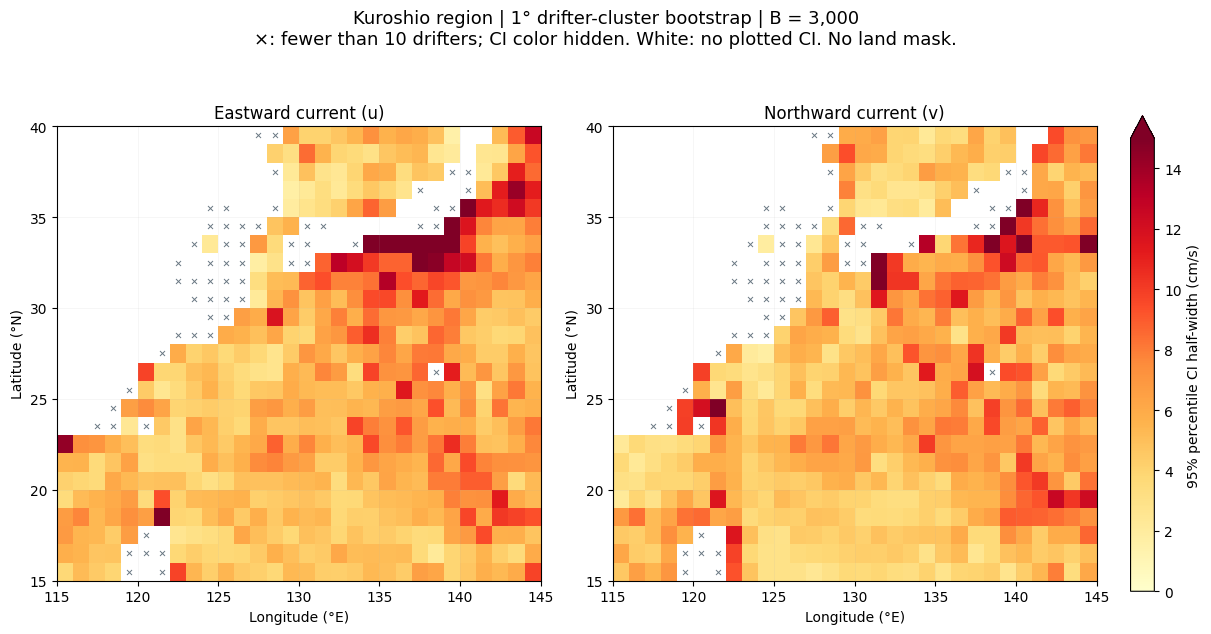

In [ ]:
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 12, 'axes.labelsize': 10,
                     'figure.facecolor': 'white', 'savefig.facecolor': 'white'})

def grid_values(column, mask_small=True):
    a = result.pivot(index='iy', columns='ix', values=column).reindex(
        index=range(NY), columns=range(NX)).to_numpy(dtype=float)
    if mask_small:
        counts = result['n_drifters'].to_numpy().reshape(NY, NX)
        a[counts < MIN_N_PLOT] = np.nan
    return np.ma.masked_invalid(a)

def map_panel(ax, column, title, norm, cmap='YlOrRd'):
    m = ax.pcolormesh(np.arange(NX + 1) + LON0, np.arange(NY + 1) + LAT0,
                      grid_values(column), cmap=cmap, norm=norm, shading='flat')
    small = result.loc[result.small_n_flag]
    ax.scatter(small.lon_center, small.lat_center, marker='x', s=13,
               c='#697782', linewidths=0.7)
    ax.set(xlim=(LON0, LON0 + NX), ylim=(LAT0, LAT0 + NY),
           title=title, xlabel='Longitude (°E)', ylabel='Latitude (°N)')
    ax.set_xticks(np.arange(115, 146, 5))
    ax.set_yticks(np.arange(15, 41, 5))
    ax.set_aspect(1 / np.cos(np.deg2rad(27.5)))
    ax.grid(alpha=0.15, linewidth=0.5)
    return m

valid = result.n_drifters >= MIN_N_PLOT
width_values = result.loc[valid, ['ve_ci_halfwidth_cmps', 'vn_ci_halfwidth_cmps']].to_numpy()
vmax = max(10.0, 5 * np.ceil(np.nanquantile(width_values, 0.98) / 5))
norm = Normalize(0, vmax)
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), layout='constrained')
for ax, component, title in zip(axes, ['ve', 'vn'], ['Eastward current (u)', 'Northward current (v)']):
    m = map_panel(ax, f'{component}_ci_halfwidth_cmps', title, norm)
fig.colorbar(m, ax=axes, shrink=0.8, pad=0.02, extend='max',
             label='95% percentile CI half-width (cm/s)')
fig.suptitle(f'Kuroshio region | 1° drifter-cluster bootstrap | B = {B:,}\n'
             '×: fewer than 10 drifters; CI color hidden. White: no plotted CI. No land mask.',
             fontsize=13)
fig.savefig(OUT_DIR / 'step3_ci_halfwidth_map.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(fig)

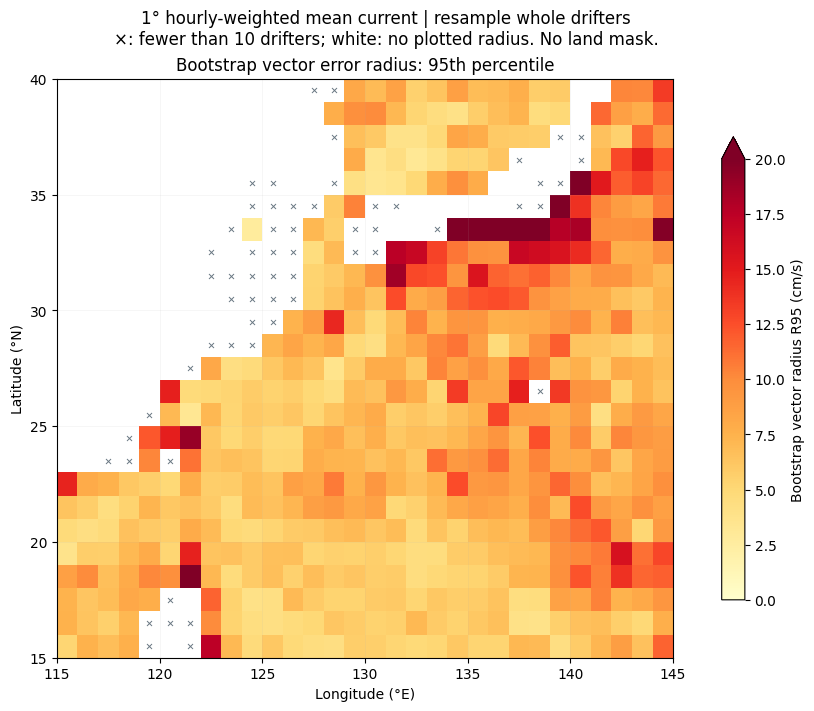

{
  "bootstrap_repetitions": 3000,
  "seed": 20261105,
  "sampled_velocity_cells": 595,
  "ci_estimable_cells_n_ge_2": 577,
  "small_sample_cells_1_to_9": 59,
  "cells_n_ge_10": 536,
  "bootstrap_only_candidates_n_ge_10_radius95_le_5cmps": 59,
  "median_ve_ci_halfwidth_cmps_n_ge_10": 5.461505172466803,
  "median_vn_ci_halfwidth_cmps_n_ge_10": 5.443094775613754,
  "median_vector_radius95_cmps_n_ge_10": 7.162584096783352
}
这些候选格不是最终 reliable 格；所需浮标数还需要 Step 4。


In [ ]:
vmax_r = max(10.0, 5 * np.ceil(np.nanquantile(result.loc[valid, 'bootstrap_vector_radius95_cmps'], 0.98) / 5))
fig, ax = plt.subplots(figsize=(8.5, 7), layout='constrained')
m = map_panel(ax, 'bootstrap_vector_radius95_cmps', 'Bootstrap vector error radius: 95th percentile',
              Normalize(0, vmax_r))
fig.colorbar(m, ax=ax, shrink=0.8, extend='max', label='Bootstrap vector radius R95 (cm/s)')
fig.suptitle('1° hourly-weighted mean current | resample whole drifters\n'
             '×: fewer than 10 drifters; white: no plotted radius. No land mask.', fontsize=12)
fig.savefig(OUT_DIR / 'step3_vector_radius95_map.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(fig)

candidate = valid & result['bootstrap_vector_radius95_cmps'].le(TARGET_CMPS)
summary = {
    'bootstrap_repetitions': B, 'seed': SEED,
    'sampled_velocity_cells': int((result.n_drifters > 0).sum()),
    'ci_estimable_cells_n_ge_2': int(result.ci_estimable.sum()),
    'small_sample_cells_1_to_9': int(result.small_n_flag.sum()),
    'cells_n_ge_10': int(valid.sum()),
    'bootstrap_only_candidates_n_ge_10_radius95_le_5cmps': int(candidate.sum()),
    'median_ve_ci_halfwidth_cmps_n_ge_10': float(result.loc[valid, 've_ci_halfwidth_cmps'].median()),
    'median_vn_ci_halfwidth_cmps_n_ge_10': float(result.loc[valid, 'vn_ci_halfwidth_cmps'].median()),
    'median_vector_radius95_cmps_n_ge_10': float(result.loc[valid, 'bootstrap_vector_radius95_cmps'].median()),
}
(OUT_DIR / 'step3_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print(json.dumps(summary, indent=2, ensure_ascii=False))
print('这些候选格不是最终 reliable 格；所需浮标数还需要 Step 4。')

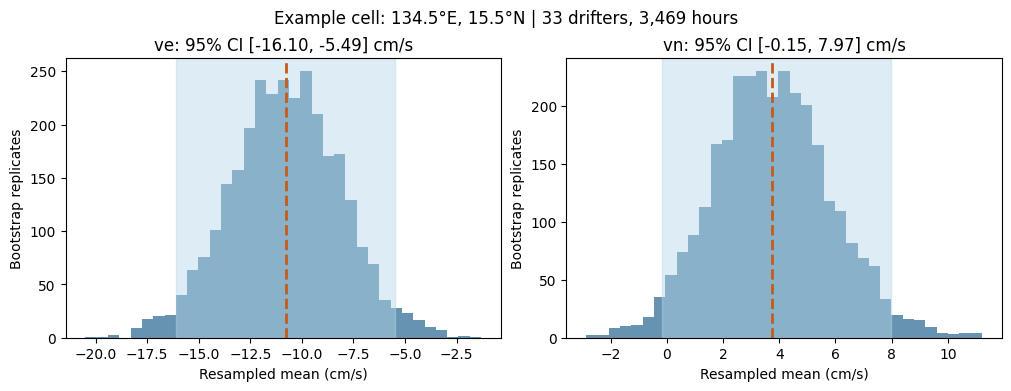

lon_center                            134.5
lat_center                             15.5
n_drifters                               33
n_hours                                3469
mean_ve_cmps                     -10.757021
ve_ci_low_cmps                   -16.098098
ve_ci_high_cmps                   -5.490499
mean_vn_cmps                        3.74143
vn_ci_low_cmps                     -0.15428
vn_ci_high_cmps                    7.969945
bootstrap_vector_radius95_cmps     6.097632


In [ ]:
observed = result.loc[result.n_drifters >= MIN_N_PLOT]
example = observed.iloc[(observed.n_drifters - observed.n_drifters.median()).abs().argmin()]
g = vel.loc[(vel.iy == example.iy) & (vel.ix == example.ix)]
rng = np.random.default_rng(np.random.SeedSequence([SEED, int(example.iy), int(example.ix), 1]))
draws = bootstrap_means(g[['sum_ve', 'sum_vn']].to_numpy(), g.n.to_numpy(), B, rng) * 100
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout='constrained')
for j, (ax, component) in enumerate(zip(axes, ['ve', 'vn'])):
    low, high = example[f'{component}_ci_low_cmps'], example[f'{component}_ci_high_cmps']
    ax.hist(draws[:, j], bins=35, color='#4c80a5', alpha=0.85)
    ax.axvspan(low, high, color='#b6d6e9', alpha=0.45)
    ax.axvline(example[f'mean_{component}_cmps'], color='#c55b19', linestyle='--', linewidth=2)
    ax.set(title=f'{component}: 95% CI [{low:.2f}, {high:.2f}] cm/s',
           xlabel='Resampled mean (cm/s)', ylabel='Bootstrap replicates')
fig.suptitle(f'Example cell: {example.lon_center:.1f}°E, {example.lat_center:.1f}°N | '
             f'{int(example.n_drifters)} drifters, {int(example.n_hours):,} hours')
fig.savefig(OUT_DIR / 'step3_example_bootstrap.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
print(example[['lon_center', 'lat_center', 'n_drifters', 'n_hours', 'mean_ve_cmps',
               've_ci_low_cmps', 've_ci_high_cmps', 'mean_vn_cmps',
               'vn_ci_low_cmps', 'vn_ci_high_cmps', 'bootstrap_vector_radius95_cmps']].to_string())

In [ ]:
sst_path = DATA_DIR / 'agg_sst_1deg.parquet'
if sst_path.exists():
    agg_sst = pd.read_parquet(sst_path)
    assert set(keys + ['n', 'sum_sst']).issubset(agg_sst.columns)
    assert agg_sst[keys + ['n', 'sum_sst']].notna().all().all()
    assert np.isfinite(agg_sst[['n', 'sum_sst']].to_numpy()).all()
    assert (agg_sst.n > 0).all() and (agg_sst.n % 1 == 0).all()
    assert agg_sst.iy.between(0, NY - 1).all() and agg_sst.ix.between(0, NX - 1).all()
    sst = (agg_sst.astype({'sum_sst': 'float64'})
           .groupby(keys, as_index=False, sort=True)[['n', 'sum_sst']].sum())
    sst_rows = []
    for (iy, ix), g in sst.groupby(['iy', 'ix'], sort=True):
        mean_c = float(g.sum_sst.sum() / g.n.sum() - 273.15)
        low = high = half = np.nan
        if len(g) >= 2:
            rng = np.random.default_rng(np.random.SeedSequence([SEED, int(iy), int(ix), 2]))
            draws_c = bootstrap_means(g[['sum_sst']].to_numpy(), g.n.to_numpy(), B, rng)[:, 0] - 273.15
            low, high = np.quantile(draws_c, [0.025, 0.975])
            half = (high - low) / 2
        sst_rows.append(dict(iy=int(iy), ix=int(ix), n_drifters=len(g), n_hours=int(g.n.sum()),
                             mean_sst_c=mean_c, sst_ci_low_c=low, sst_ci_high_c=high,
                             sst_ci_halfwidth_c=half))
    sst_result = pd.DataFrame(sst_rows).set_index(['iy', 'ix']).reindex(full_index).reset_index()
    for name in ['n_drifters', 'n_hours']:
        sst_result[name] = sst_result[name].fillna(0).astype('int64')
    sst_result['lon_center'] = LON0 + sst_result.ix + 0.5
    sst_result['lat_center'] = LAT0 + sst_result.iy + 0.5
    sst_result['ci_estimable'] = sst_result.n_drifters >= 2
    sst_result['small_n_flag'] = sst_result.n_drifters.between(1, MIN_N_PLOT - 1)
    sst_result['n_bootstrap'] = np.where(sst_result.ci_estimable, B, 0)
    sst_result.to_parquet(OUT_DIR / 'step3_sst_1deg.parquet', index=False)
    sst_result.to_csv(OUT_DIR / 'step3_sst_1deg.csv', index=False)
    print(f'SST: {len(agg_sst):,} rows → {len(sst):,} cell–drifter records; '
          f'{(sst_result.n_drifters > 0).sum()} cells have data. Exported.')
else:
    print('SST aggregate not found; skipping SST. Velocity results are unaffected.')

SST: 48,511 rows → 45,777 cell–drifter records; 618 cells have data. Exported.
